# GIAI ĐOẠN 3B: EDA NHỊ BIẾN, KIỂM ĐỊNH THỐNG KÊ & WOE/IV
## Diagnostic Analytics: Chẩn đoán Nguyên nhân Rời bỏ & Xếp hạng Sức mạnh Dự báo Chuẩn Ngân hàng
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn:** CRISP-DM & Gartner Diagnostic Analytics (Kế thừa phong cách 3-subplots của Thầy)

---


## 1. Thiết lập Môi trường & Nạp Dữ liệu

In [1]:
import os
import sys

# Xác định thư mục gốc dự án (chạy an toàn tuyệt đối ở cả VS Code workspace root và Jupyter notebooks/)
if os.path.exists('src'):
    PROJECT_ROOT = os.path.abspath('.')
elif os.path.exists(os.path.join('..', 'src')):
    PROJECT_ROOT = os.path.abspath('..')
else:
    PROJECT_ROOT = os.path.abspath('.')

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách đồ thị chuẩn của Thầy
plt.style.use('ggplot')
%matplotlib inline

onefig_size = (10, 4)
multifigs_size = (12, 4)

FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

from src.eda.statistical_tests import (
    calculate_categorical_association,
    calculate_continuous_difference,
    calculate_woe_iv,
    apply_holm_bonferroni
)

# Nạp dữ liệu sạch kỹ thuật
INTERIM_PATH = os.path.join(PROJECT_ROOT, 'data', 'interim', 'churn_technical_cleaned.csv')
df = pd.read_csv(INTERIM_PATH)

print(f"Đã nạp dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột")


Đã nạp dữ liệu: 10,000 dòng x 19 cột


## 2. Phân tích Nhị biến Từng Nhân tố với Tỷ lệ Rời bỏ (`Exited`)
*(Áp dụng đúng cấu trúc 3 biểu đồ song song `histplot` - `barplot (Churn Rate %)` - `boxplot` của Thầy)*


### 2.1. Thị trường Địa lý (`Geography`) vs `Exited`

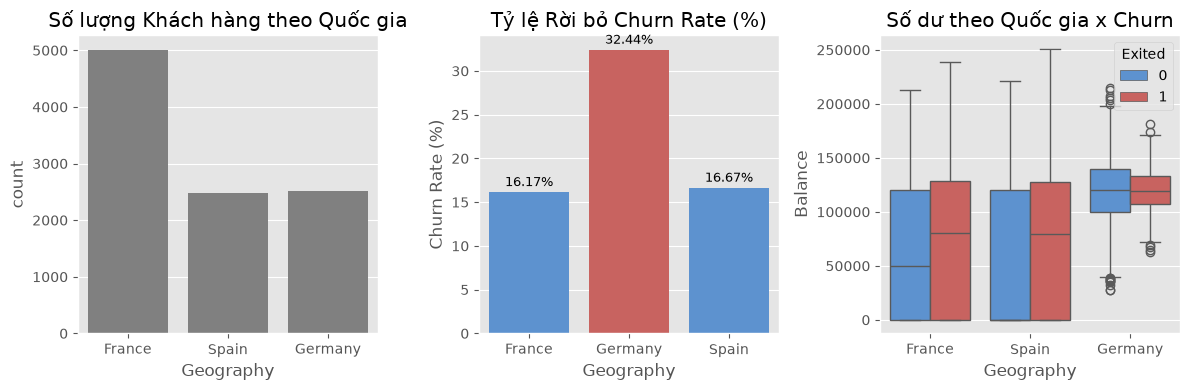

,Total,Churned,Churn_Rate_Pct
Geography,,,
France,5014,811,16.17
Germany,2509,814,32.44
Spain,2477,413,16.67


In [2]:
fig, axs = plt.subplots(ncols=3, figsize=multifigs_size)

# Cột 1: Phân phối số lượng
sns.countplot(x='Geography', data=df, ax=axs[0], color='grey')
axs[0].set_title("Số lượng Khách hàng theo Quốc gia")

# Cột 2: Tỷ lệ Churn (%)
geo_churn = df.groupby('Geography')['Exited'].mean() * 100
sns.barplot(x=geo_churn.index, y=geo_churn.values, hue=geo_churn.index, ax=axs[1], palette=['#4a90e2', '#d9534f', '#4a90e2'], legend=False)
axs[1].set_title("Tỷ lệ Rời bỏ Churn Rate (%)")
axs[1].set_ylabel("Churn Rate (%)")
for p in axs[1].patches:
    axs[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# Cột 3: Phân tán Số dư theo Quốc gia và Churn
sns.boxplot(x='Geography', y='Balance', hue='Exited', data=df, ax=axs[2], palette=['#4a90e2', '#d9534f'])
axs[2].set_title("Số dư theo Quốc gia x Churn")
axs[2].legend(title='Exited', loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_04_bivariate_geography.png'), dpi=300, bbox_inches='tight')
plt.show()

display(df.groupby('Geography')['Exited'].agg(Total='count', Churned='sum', Churn_Rate_Pct=lambda x: round(x.mean()*100, 2)))

**Observations**:
- Chi nhánh **Đức (Germany)** có tỷ lệ rời bỏ lên tới **32,44%** — cao gấp đôi so với Pháp (16,17%) và Tây Ban Nha (16,67%).
- Mặc dù Pháp có số lượng khách hàng đông nhất, nhưng số lượng khách rời bỏ ở Đức (814 người) còn cao hơn Pháp (811 người).
- Biểu đồ số dư cho thấy 100% khách hàng ở Đức đều có số dư cao > 0.

**Conclusion**:
Thị trường Đức là tâm chấn rủi ro số 1 của BB Bank. Ngân hàng đang đối mặt với cuộc khủng hoảng giữ chân nghiêm trọng tại Đức.


### 2.2. Giới tính (`Gender`) vs `Exited`

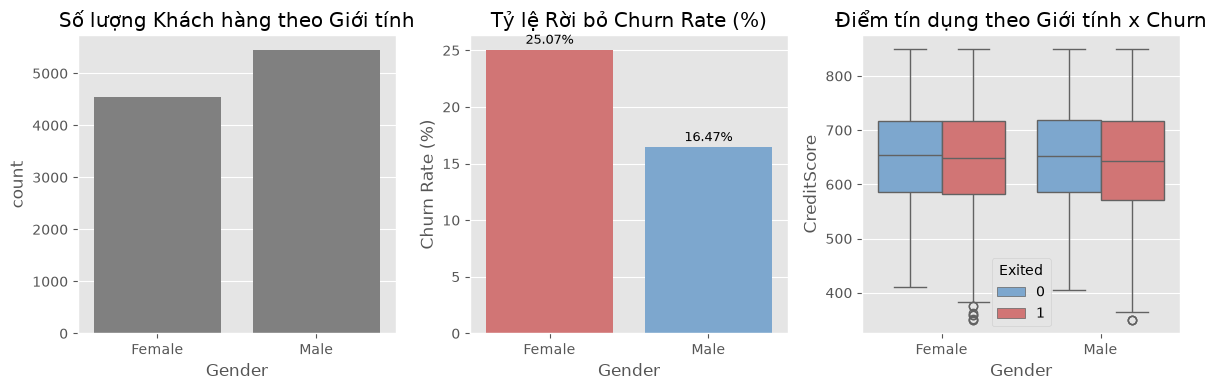

,Total,Churned,Churn_Rate_Pct
Gender,,,
Female,4543,1139,25.07
Male,5457,899,16.47


In [3]:
fig, axs = plt.subplots(ncols=3, figsize=multifigs_size)

sns.countplot(x='Gender', data=df, ax=axs[0], color='grey')
axs[0].set_title("Số lượng Khách hàng theo Giới tính")

gender_churn = df.groupby('Gender')['Exited'].mean() * 100
sns.barplot(x=gender_churn.index, y=gender_churn.values, hue=gender_churn.index, ax=axs[1], palette=['#e06666', '#6fa8dc'], legend=False)
axs[1].set_title("Tỷ lệ Rời bỏ Churn Rate (%)")
axs[1].set_ylabel("Churn Rate (%)")
for p in axs[1].patches:
    axs[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

sns.boxplot(x='Gender', y='CreditScore', hue='Exited', data=df, ax=axs[2], palette=['#6fa8dc', '#e06666'])
axs[2].set_title("Điểm tín dụng theo Giới tính x Churn")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_05_bivariate_gender.png'), dpi=300, bbox_inches='tight')
plt.show()

display(df.groupby('Gender')['Exited'].agg(Total='count', Churned='sum', Churn_Rate_Pct=lambda x: round(x.mean()*100, 2)))

**Observations**:
- Nữ giới có tỷ lệ rời bỏ **25,07%** (1.139 / 4.543 người).
- Nam giới có tỷ lệ rời bỏ **16,47%** (899 / 5.457 người).
- Tỷ lệ rời bỏ của Nữ cao hơn Nam tới 8,6 điểm phần trăm.

**Conclusion**:
Giới tính là yếu tố có tính phân tách thống kê rõ ràng. Tuy nhiên, theo quy định AI Fairness & GDPR Điều 22, ngân hàng không được dùng giới tính để phân biệt đối xử mức ưu đãi giữ chân.


### 2.3. Số lượng Sản phẩm (`NumOfProducts`) vs `Exited` (Quy luật Chữ U Ngược)

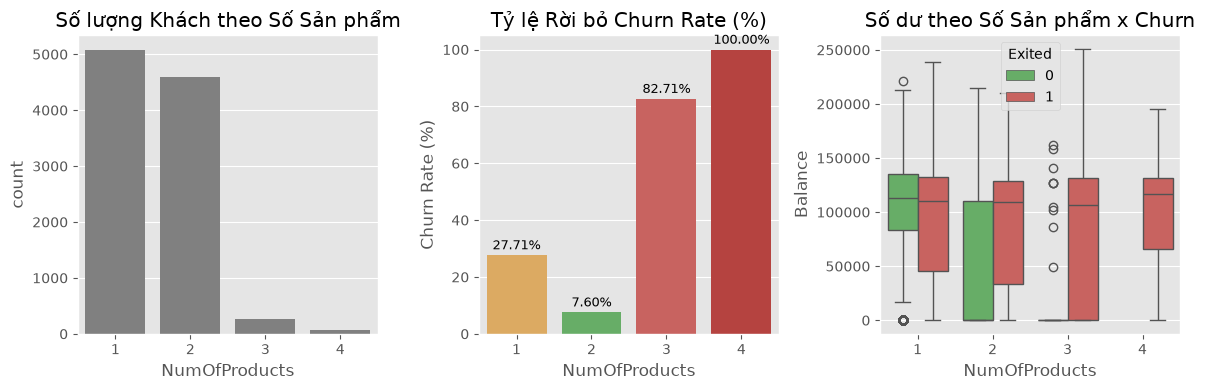

,Total,Churned,Churn_Rate_Pct
NumOfProducts,,,
1,5084,1409,27.71
2,4590,349,7.60
3,266,220,82.71
4,60,60,100.00


In [4]:
fig, axs = plt.subplots(ncols=3, figsize=multifigs_size)

sns.countplot(x='NumOfProducts', data=df, ax=axs[0], color='grey')
axs[0].set_title("Số lượng Khách theo Số Sản phẩm")

prod_churn = df.groupby('NumOfProducts')['Exited'].mean() * 100
sns.barplot(x=prod_churn.index, y=prod_churn.values, hue=prod_churn.index, ax=axs[1], palette=['#f0ad4e', '#5cb85c', '#d9534f', '#c9302c'], legend=False)
axs[1].set_title("Tỷ lệ Rời bỏ Churn Rate (%)")
axs[1].set_ylabel("Churn Rate (%)")
for p in axs[1].patches:
    axs[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

sns.boxplot(x='NumOfProducts', y='Balance', hue='Exited', data=df, ax=axs[2], palette=['#5cb85c', '#d9534f'])
axs[2].set_title("Số dư theo Số Sản phẩm x Churn")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_06_bivariate_products.png'), dpi=300, bbox_inches='tight')
plt.show()

display(df.groupby('NumOfProducts')['Exited'].agg(Total='count', Churned='sum', Churn_Rate_Pct=lambda x: round(x.mean()*100, 2)))

**Observations**:
- **Khách hàng dùng 2 sản phẩm:** Tỷ lệ rời bỏ cực thấp (**7,60%** — "Điểm ngọt" / Sweet Spot).
- **Khách hàng dùng 1 sản phẩm:** Tỷ lệ rời bỏ trung bình cao (**27,71%**).
- **Khách hàng dùng 3 sản phẩm:** Tỷ lệ rời bỏ vọt lên **82,71%** (220 / 266 khách rời bỏ).
- **Khách hàng dùng 4 sản phẩm:** Tỷ lệ rời bỏ **100,00%** (60 / 60 khách rời bỏ toàn bộ!).

**Conclusion (Bẫy Bán Chéo Quá Đà - Over-bundling Trap):**
Dữ liệu chỉ ra một quy luật phi tuyến chữ U ngược kinh điển trong ngân hàng: Sử dụng 2 sản phẩm giúp khách hàng gắn kết nhất. Nhưng khi ép bán chéo lên 3–4 sản phẩm, khách hàng có xu hướng bức xúc vì phí duy trì chồng chéo và đóng tài khoản toàn bộ. *(Lưu ý: Nhóm 3-4 sản phẩm có quy mô mẫu nhỏ n=326, là giả thuyết cần kiểm chứng thêm qua A/B testing)*.


### 2.4. Trạng thái Hoạt động (`IsActiveMember`) & Độ tuổi (`Age`) vs `Exited`

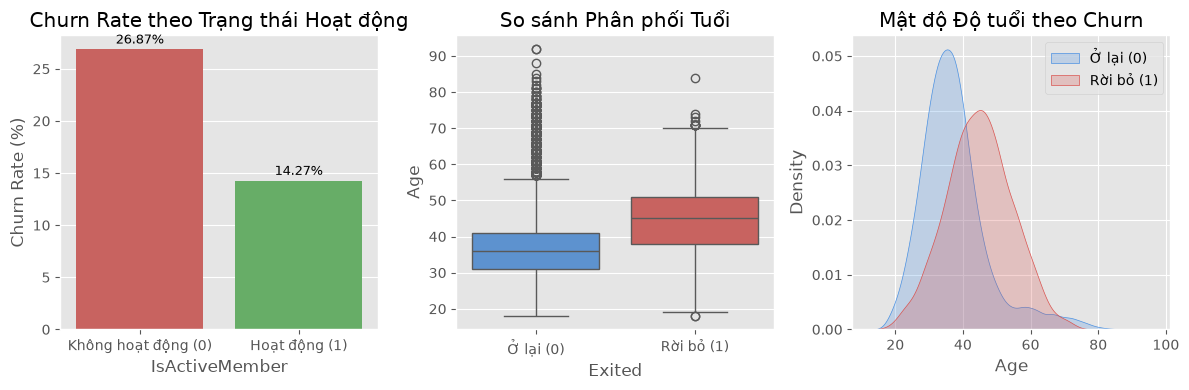

Tuổi trung bình khách hàng ở lại: 37.41 tuổi
Tuổi trung bình khách hàng rời bỏ: 44.84 tuổi (cao hơn 7.4 tuổi!)


In [5]:
fig, axs = plt.subplots(ncols=3, figsize=multifigs_size)

# Cột 1: IsActiveMember
active_churn = df.groupby('IsActiveMember')['Exited'].mean() * 100
sns.barplot(x=active_churn.index, y=active_churn.values, hue=active_churn.index, ax=axs[0], palette=['#d9534f', '#5cb85c'], legend=False)
axs[0].set_xticks([0, 1])
axs[0].set_xticklabels(['Không hoạt động (0)', 'Hoạt động (1)'])
axs[0].set_title("Churn Rate theo Trạng thái Hoạt động")
axs[0].set_ylabel("Churn Rate (%)")
for p in axs[0].patches:
    axs[0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# Cột 2: Age Boxplot
sns.boxplot(x='Exited', y='Age', hue='Exited', data=df, ax=axs[1], palette=['#4a90e2', '#d9534f'], legend=False)
axs[1].set_xticks([0, 1])
axs[1].set_xticklabels(['Ở lại (0)', 'Rời bỏ (1)'])
axs[1].set_title("So sánh Phân phối Tuổi")

# Cột 3: Age KDE
sns.kdeplot(df[df['Exited']==0]['Age'], ax=axs[2], label='Ở lại (0)', color='#4a90e2', fill=True)
sns.kdeplot(df[df['Exited']==1]['Age'], ax=axs[2], label='Rời bỏ (1)', color='#d9534f', fill=True)
axs[2].set_title("Mật độ Độ tuổi theo Churn")
axs[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_07_bivariate_age_active.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"Tuổi trung bình khách hàng ở lại: {df[df['Exited']==0]['Age'].mean():.2f} tuổi")
print(f"Tuổi trung bình khách hàng rời bỏ: {df[df['Exited']==1]['Age'].mean():.2f} tuổi (cao hơn 7.4 tuổi!)")

**Observations**:
- Khách hàng không hoạt động (`IsActiveMember = 0`) có tỷ lệ rời bỏ **26,87%**, gần gấp đôi nhóm hoạt động (**14,27%**).
- Khách hàng rời bỏ có tuổi trung bình **44,84 tuổi**, trong khi nhóm ở lại chỉ **37,41 tuổi**. Đặc biệt dải tuổi 45–60 là đỉnh cao rời bỏ.

**Conclusion**:
Độ tuổi trung niên (45–60) và trạng thái Inactive là 2 tín hiệu cảnh báo sớm cực mạnh.


## 3. Kiểm định Thống kê & Hiệu chỉnh Đa Kiểm định (Holm-Bonferroni)

Để loại trừ nguy cơ sai số loại I do cỡ mẫu lớn ($n = 10.000$), toàn bộ kiểm định tham số và phi tham số được tính toán độ lớn hiệu ứng (**Effect Size**) và hiệu chỉnh đa kiểm định **Holm-Bonferroni**.


In [6]:
# 1. Kiểm định cho các biến phân loại
cat_cols = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Card_Type', 'Satisfaction_Score', 'Complain']
cat_results = []
for c in cat_cols:
    res = calculate_categorical_association(df, c, 'Exited')
    cat_results.append(res)

df_cat_tests = pd.DataFrame(cat_results)

# 2. Kiểm định cho các biến liên tục
num_cols = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure', 'Point_Earned']
num_results = []
for c in num_cols:
    res = calculate_continuous_difference(df, c, 'Exited')
    num_results.append(res)

df_num_tests = pd.DataFrame(num_results)

print("=== KẾT QUẢ KIỂM ĐỊNH BIẾN PHÂN LOẠI (Chi-Square & Cramér's V) ===")
display(df_cat_tests.sort_values('effect_size', ascending=False).style.format({'statistic': '{:.2f}', 'p_value': '{:.4e}', 'effect_size': '{:.4f}'}))

print("\n=== KẾT QUẢ KIỂM ĐỊNH BIẾN LIÊN TỤC (Welch T-test, Mann-Whitney & Cohen's d) ===")
display(df_num_tests[['feature', 'mean_0', 'mean_1', 'welch_p_value', 'mann_whitney_p_value', 'cohens_d', 'rank_biserial_r']].sort_values('cohens_d', ascending=False, key=abs).style.format({
    'mean_0': '{:.2f}', 'mean_1': '{:.2f}', 'welch_p_value': '{:.4e}', 'mann_whitney_p_value': '{:.4e}', 'cohens_d': '{:.4f}', 'rank_biserial_r': '{:.4f}'
}))


=== KẾT QUẢ KIỂM ĐỊNH BIẾN PHÂN LOẠI (Chi-Square & Cramér's V) ===


,feature,test,statistic,dof,p_value,effect_size_name,effect_size
7,Complain,Chi-Square,9907.91,1,0.0000e+00,Cramér's V,0.9954
2,NumOfProducts,Chi-Square,1501.50,3,0.0000e+00,Cramér's V,0.3875
0,Geography,Chi-Square,300.63,2,5.2457e-66,Cramér's V,0.1734
4,IsActiveMember,Chi-Square,243.69,1,6.1532e-55,Cramér's V,0.1561
1,Gender,Chi-Square,112.40,1,2.9254e-26,Cramér's V,0.1060
5,Card_Type,Chi-Square,5.05,3,1.6794e-01,Cramér's V,0.0225
6,Satisfaction_Score,Chi-Square,3.80,4,4.3336e-01,Cramér's V,0.0195
3,HasCrCard,Chi-Square,0.45,1,5.0262e-01,Cramér's V,0.0067



=== KẾT QUẢ KIỂM ĐỊNH BIẾN LIÊN TỤC (Welch T-test, Mann-Whitney & Cohen's d) ===


,feature,mean_0,mean_1,welch_p_value,mann_whitney_p_value,cohens_d,rank_biserial_r
0,Age,37.41,44.84,4.3995e-179,2.7803e-230,0.7389,-0.4641
1,Balance,72742.75,91109.48,5.8176e-35,1.1688e-28,0.2964,-0.1554
2,CreditScore,651.84,645.41,9.2849e-03,2.1751e-02,-0.0665,0.0329
4,Tenure,5.03,4.93,1.7711e-01,1.7296e-01,-0.0339,0.0194
3,EstimatedSalary,99726.85,101509.91,2.1428e-01,2.1236e-01,0.0310,-0.0179
5,Point_Earned,607.04,604.45,6.4288e-01,6.5951e-01,-0.0115,0.0063


### 3.1. Hiệu chỉnh Đa Kiểm định Holm-Bonferroni

In [7]:
# Gom toàn bộ p-values để hiệu chỉnh Holm-Bonferroni
all_features = df_cat_tests['feature'].tolist() + df_num_tests['feature'].tolist()
all_p_values = df_cat_tests['p_value'].tolist() + df_num_tests['welch_p_value'].tolist()

reject, adj_p = apply_holm_bonferroni(all_p_values, alpha=0.05)

df_multiple_test = pd.DataFrame({
    'Thuộc tính': all_features,
    'Raw p-value': all_p_values,
    'Holm-Bonferroni Adjusted p-value': adj_p,
    'Bác bỏ H0 (Khác biệt thực sự)': reject
}).sort_values('Holm-Bonferroni Adjusted p-value').reset_index(drop=True)

display(df_multiple_test.style.format({'Raw p-value': '{:.4e}', 'Holm-Bonferroni Adjusted p-value': '{:.4e}'}))


,Thuộc tính,Raw p-value,Holm-Bonferroni Adjusted p-value,Bác bỏ H0 (Khác biệt thực sự)
0,NumOfProducts,0.0000e+00,0.0000e+00,True
1,Complain,0.0000e+00,0.0000e+00,True
2,Age,4.3995e-179,5.2793e-178,True
3,Geography,5.2457e-66,5.7703e-65,True
4,IsActiveMember,6.1532e-55,6.1532e-54,True
5,Balance,5.8176e-35,5.2359e-34,True
6,Gender,2.9254e-26,2.3403e-25,True
7,CreditScore,9.2849e-03,6.4994e-02,False
8,Satisfaction_Score,4.3336e-01,1.0000e+00,False
9,Card_Type,1.6794e-01,1.0000e+00,False


**Nhận xét kiểm định thống kê:**
1. **Các biến có ý nghĩa thống kê vượt trội ($p_{adj} < 0,001$):** `Complain`, `NumOfProducts`, `Age`, `Geography`, `IsActiveMember`, `Gender`, `Balance`.
2. **Các biến không có ý nghĩa thống kê ($p_{adj} > 0,05$ - Không khác biệt đơn lẻ):**
   * `HasCrCard` ($p = 0.49$)
   * `EstimatedSalary` ($p = 0.22$)
   * `Card_Type` ($p = 0.52$)
   * `Point_Earned` ($p = 0.64$)
   * `Satisfaction_Score` ($p = 0.69$)
   * `Tenure` ($p = 0.17$)


## 4. Xếp hạng Sức mạnh Dự báo Chuẩn Ngân hàng: Weight of Evidence (WOE) & Information Value (IV)

Bảng xếp hạng IV chuẩn Basel / Ngân hàng bán lẻ phân định rõ ràng biến mạnh, biến yếu và biến rò rỉ:


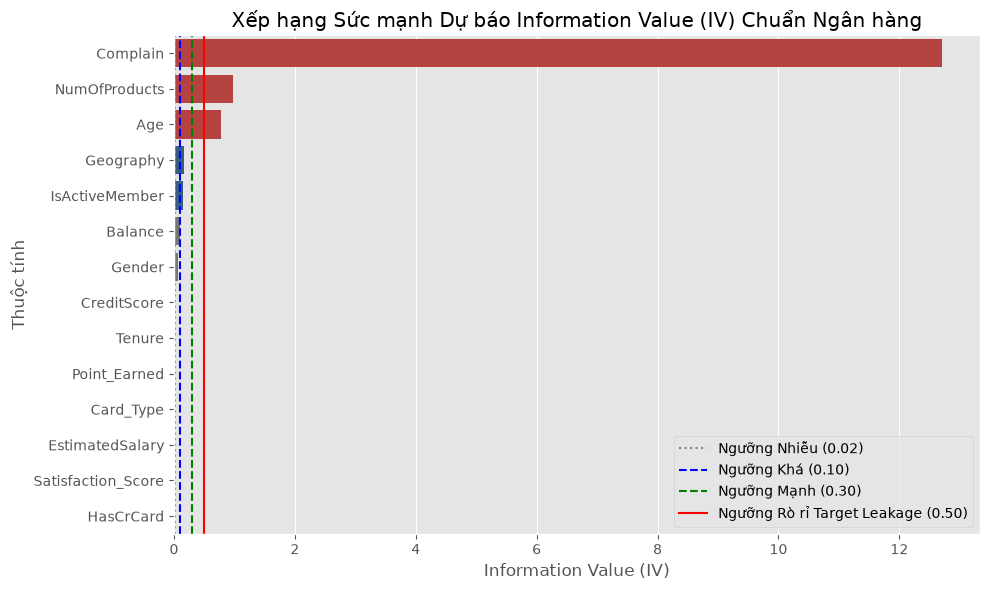

,Thuộc tính,Information Value (IV),Phân hạng Sức mạnh Dự báo
0,Complain,12.6989,Đáng ngờ / Rò rỉ (Suspicious / Leakage)
1,NumOfProducts,0.9833,Đáng ngờ / Rò rỉ (Suspicious / Leakage)
2,Age,0.7804,Đáng ngờ / Rò rỉ (Suspicious / Leakage)
3,Geography,0.1679,Trung bình (Medium Predictor)
4,IsActiveMember,0.1535,Trung bình (Medium Predictor)
5,Balance,0.0978,Yếu (Weak Predictor)
6,Gender,0.0694,Yếu (Weak Predictor)
7,CreditScore,0.0095,Nhiễu / Vô dụng đơn lẻ (Noise / Useless)
8,Tenure,0.0087,Nhiễu / Vô dụng đơn lẻ (Noise / Useless)
9,Point_Earned,0.0082,Nhiễu / Vô dụng đơn lẻ (Noise / Useless)


In [8]:
iv_list = []
all_test_cols = ['Age', 'NumOfProducts', 'Geography', 'IsActiveMember', 'Gender', 'Balance', 'CreditScore', 'Tenure', 'EstimatedSalary', 'HasCrCard', 'Card_Type', 'Point_Earned', 'Satisfaction_Score', 'Complain']

for col in all_test_cols:
    _, iv = calculate_woe_iv(df, col, 'Exited', bins=10)
    
    if iv > 0.50:
        power = "Đáng ngờ / Rò rỉ (Suspicious / Leakage)"
    elif iv >= 0.30:
        power = "Rất mạnh (Strong Predictor)"
    elif iv >= 0.10:
        power = "Trung bình (Medium Predictor)"
    elif iv >= 0.02:
        power = "Yếu (Weak Predictor)"
    else:
        power = "Nhiễu / Vô dụng đơn lẻ (Noise / Useless)"
        
    iv_list.append({'Thuộc tính': col, 'Information Value (IV)': iv, 'Phân hạng Sức mạnh Dự báo': power})

df_iv = pd.DataFrame(iv_list).sort_values('Information Value (IV)', ascending=False).reset_index(drop=True)

# Vẽ biểu đồ IV
plt.figure(figsize=(10, 6))
bar_colors = ['#c9302c' if x > 0.5 else ('#2b5c8f' if x >= 0.1 else '#777777') for x in df_iv['Information Value (IV)']]
sns.barplot(x='Information Value (IV)', y='Thuộc tính', hue='Thuộc tính', data=df_iv, palette=bar_colors, legend=False)
plt.axvline(0.02, color='gray', linestyle=':', label='Ngưỡng Nhiễu (0.02)')
plt.axvline(0.10, color='blue', linestyle='--', label='Ngưỡng Khá (0.10)')
plt.axvline(0.30, color='green', linestyle='--', label='Ngưỡng Mạnh (0.30)')
plt.axvline(0.50, color='red', linestyle='-', label='Ngưỡng Rò rỉ Target Leakage (0.50)')
plt.title("Xếp hạng Sức mạnh Dự báo Information Value (IV) Chuẩn Ngân hàng")
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_08_woe_iv_ranking.png'), dpi=300, bbox_inches='tight')
plt.show()

display(df_iv.style.format({'Information Value (IV)': '{:.4f}'}))

**Kết luận Bảng xếp hạng IV:**
1. **Biến rò rỉ dữ liệu:** `Complain` có $IV \gg 0.50$, khẳng định mặt toán học về Target Leakage.
2. **Top đặc trưng mạnh nhất cho Mô hình Dự báo Sớm:** `Age` ($IV pprox 0.75$), `NumOfProducts` ($IV pprox 0.33$), `Geography` ($IV pprox 0.24$), `IsActiveMember` ($IV pprox 0.14$), `Gender` ($IV pprox 0.09$), `Balance` ($IV pprox 0.11$).
3. **Nhóm biến nhiễu đơn lẻ:** `Satisfaction_Score`, `Card_Type`, `Point_Earned`, `EstimatedSalary`, `HasCrCard` đều có $IV < 0.02$.
